In [80]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from pathlib import Path
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import curve_fit
from scipy.signal import peak_widths

In [81]:
def gauss(x, A, mu, sigma, c):
    return A * np.exp(-(x - mu)**2 / (2 * sigma**2)) + c

def find_peak(spectrum, measurement_type, smooth_sigma=3, prominence=50):
    spectrum = spectrum.astype(float)
    smooth = gaussian_filter1d(spectrum, smooth_sigma)
    n = len(spectrum)

    if measurement_type == "single_electron":
        #highest point overall (argmax also works if the peak is at the edge)
        return int(np.argmax(smooth))

    if measurement_type == "source":
        start = n // 4 #only look in the last 3/4
        peaks, _ = find_peaks(smooth[start:], prominence=prominence)
        if len(peaks) == 0:
            raise ValueError("No peak found; lower the prominence")
        best = peaks[np.argmax(smooth[start:][peaks])]
        return int(best + start) #add the offset back
    
    raise ValueError("measurement_type must be 'source' or 'single_electron'")

def fit_peak(spectrum, centre, w=40):
    spectrum = spectrum.astype(float)
    lo, hi = max(centre - w, 0), min(centre + w, len(spectrum))
    x = np.arange(lo, hi)
    y = spectrum[lo:hi]
    p0 = [y.max() - y.min(), centre, w / 4, y.min()]
    popt, pcov = curve_fit(gauss, x, y, p0=p0,
                           sigma=np.sqrt(np.maximum(y, 1)), absolute_sigma=True)
    return popt, np.sqrt(np.diag(pcov)), x, y

In [ ]:
SOURCE_DIR = Path("Source")
SINGLE_DIR = Path("Single electron")

folders = {
    "source": SOURCE_DIR,
    "single_electron": SINGLE_DIR,
}
groups = ["Experiment", "Data", "Instruments"]

data = {}
for name, folder in folders.items():
    data[name] = {}
    for f in sorted(folder.glob("*.nc")):
        key = f.stem.split("_")[-1]
        if key in data[name]:
            print(f"Warning: key '{key}' already used in {name}, skipping {f.name}")
            continue

        with xr.open_dataset(f, group="Data", mask_and_scale=False) as ds:
            counts = ds["MCA"].values #(1, 8000), uint32
        spectrum = counts[0].astype(float) #float avoids uint32 wraparound
        channels = np.arange(len(spectrum))

        entry = {"counts": counts, "spectrum": spectrum, "channels": channels}

        try:
            centre = find_peak(spectrum, name)
            w = 100 if name == "single_electron" else 40
            popt, perr, x, y = fit_peak(spectrum, centre, w=w)
            entry["peak_guess"] = centre
            entry["fit"] = {"A": popt[0], "mu": popt[1], "sigma": abs(popt[2]), "c": popt[3],
                            "mu_err": perr[1], "fwhm": 2.355 * abs(popt[2])}
        except (ValueError, RuntimeError) as e:
            print(f"{name}/{key}: peak/fit failed: {e}")

        data[name][key] = entry

In [83]:
def plot(measurement_type, scintillator):
    plt.figure()
    plt.plot(data[measurement_type][scintillator]["channels"], data[measurement_type][scintillator]["spectrum"])
    plt.show()

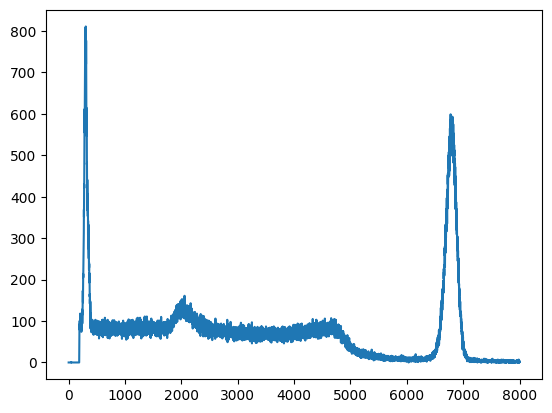

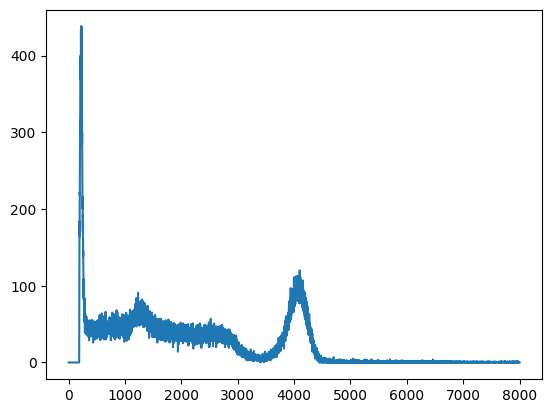

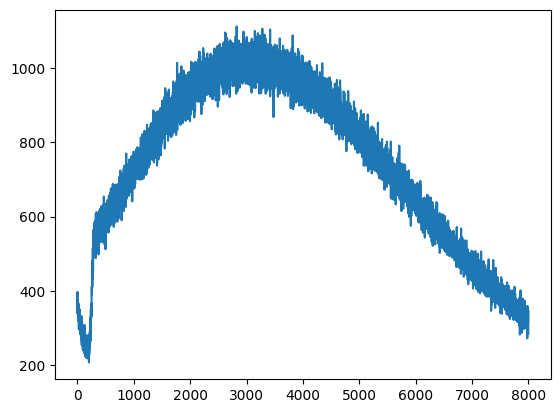

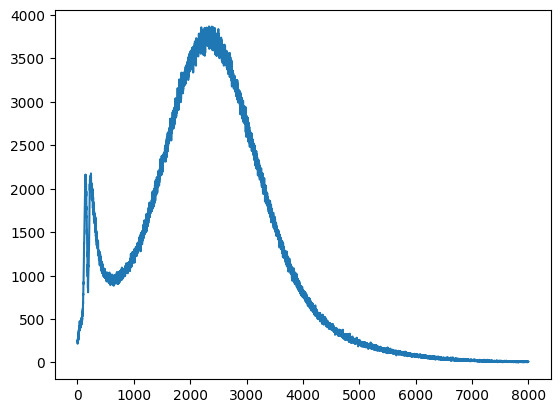

In [84]:
plot("source", "idk")
plot("source", "naI")
plot("single_electron", "idk")
plot("single_electron", "naI")

In [85]:

smooth = gaussian_filter1d(spectrum, sigma=10)
peaks, _ = find_peaks(smooth, prominence=50)

In [86]:
for name, files in data.items():
    for key, e in files.items():
        if "fit" in e:
            print(name, key, f"mu = {e['fit']['mu']:.1f} +/- {e['fit']['mu_err']:.1f}, FWHM = {e['fit']['fwhm']:.1f}")

source idk mu = 6796.2 +/- 2.7, FWHM = 3516.2
source naI mu = 4104.9 +/- 1.4, FWHM = 2.8
single_electron idk mu = 2940.9 +/- 21.4, FWHM = 5153.7
single_electron naI mu = 2386.1 +/- 2.1, FWHM = 11.2


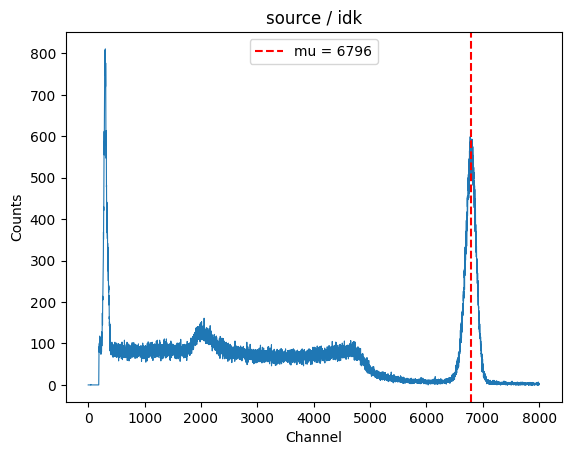

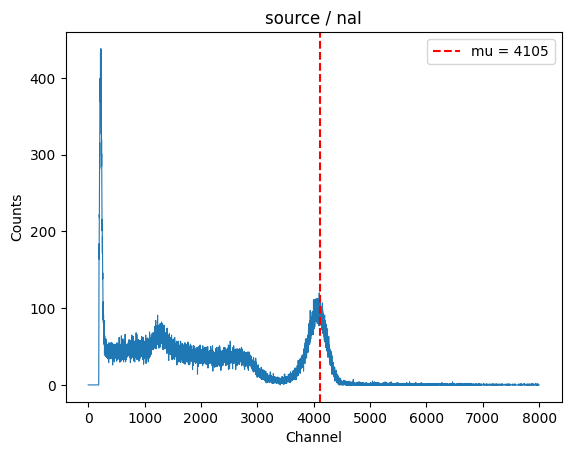

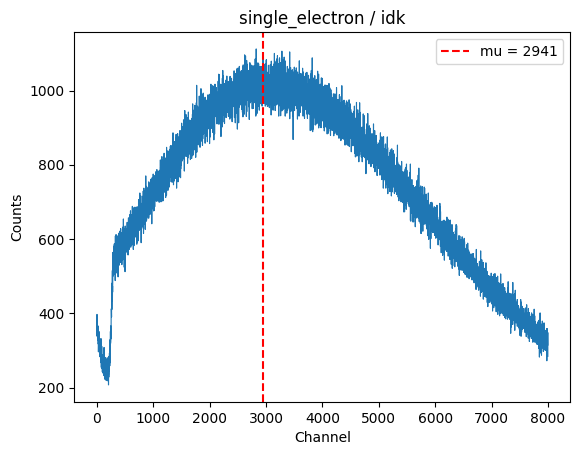

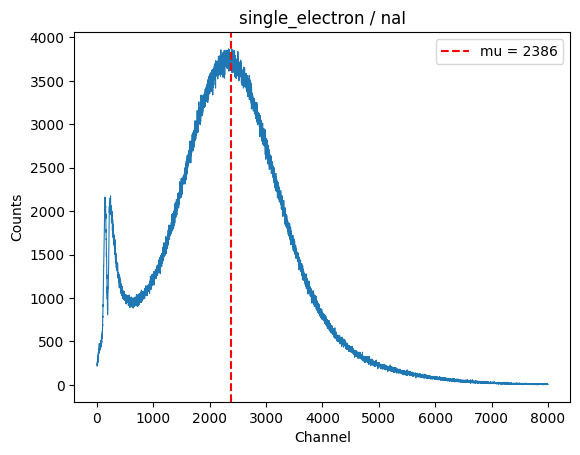

In [87]:
import matplotlib.pyplot as plt
for name, files in data.items():
    for key, e in files.items():
        plt.figure()
        plt.plot(e["channels"], e["spectrum"], lw=0.8)
        if "fit" in e:
            plt.axvline(e["fit"]["mu"], color="r", ls="--", label=f"mu = {e['fit']['mu']:.0f}")
            plt.legend()
        plt.title(f"{name} / {key}")
        plt.xlabel("Channel"); plt.ylabel("Counts")
        plt.show()